# 📈 Regression Metrics & Generalization Analysis

In regression, we are not predicting a class but a **continuous value** (here:
median house value in units of $100,000). The confusion matrix, sensitivity, and
AUC from classification do not apply. Instead, we assess **how far off** the
predictions are, and **how much variance** the model explains.

---

## 1. Error-Based Metrics (Lower is Better)

### MAE — Mean Absolute Error
$$\text{MAE} = \frac{1}{n}\sum |y_i - \hat{y}_i|$$
The average absolute difference between prediction and truth, in the **same
units as the target**. If the target is in $100,000s, an MAE of 0.4 means the
model is typically off by $40,000. **Robust to outliers** because errors are
not squared .

### MSE — Mean Squared Error
$$\text{MSE} = \frac{1}{n}\sum (y_i - \hat{y}_i)^2$$
Squares each error before averaging. **Heavily penalizes large mistakes** — a
single prediction that is very wrong dominates the score. The units are squared,
so MSE is hard to interpret directly .

### RMSE — Root Mean Squared Error
$$\text{RMSE} = \sqrt{\text{MSE}}$$
Brings MSE back to the **original units**, making it interpretable like MAE.
Because of the square root, RMSE is **more sensitive to large errors** than MAE.
Comparing MAE and RMSE is diagnostic: if RMSE ≫ MAE, the model makes a few very
large errors (outliers), not just uniformly small ones [citation:11].

### MAPE — Mean Absolute Percentage Error
$$\text{MAPE} = \frac{100\%}{n}\sum \left|\frac{y_i - \hat{y}_i}{y_i}\right|$$
Expresses error as a **percentage of the true value**, making it comparable
across datasets with different scales. **Problematic when y is near zero** —
the percentage explodes. Use with caution if the target can be small .

### MSLE — Mean Squared Logarithmic Error
$$\text{MSLE} = \frac{1}{n}\sum (\log(1+y_i) - \log(1+\hat{y}_i))^2$$
Penalizes **under-prediction more than over-prediction** and reduces sensitivity
to large absolute errors. Useful when the target spans several orders of
magnitude .

---

## 2. Variance-Based Metric (Higher is Better)

### R² — Coefficient of Determination
$$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$
The **proportion of variance in the target explained by the model**. R² = 1 is
perfect; R² = 0 means the model is no better than always predicting the mean;
R² can go **negative** if the model is worse than the mean baseline .

---

## 3. Cross-Validation & Generalization

All metrics are computed with **5-fold cross-validation** on the training set.
`cross_validate` returns one score per fold; we report the **mean** and
**standard deviation** across folds. The standard deviation tells you how
*stable* the model is — a large std means the score depends heavily on which
data was held out.

The **generalization gap** is computed on a separate test set:
$$\text{Gap} = \text{Test Error} - \text{Train Error}$$
A large positive gap (test error much higher than train error) signals
**overfitting**. Both errors high and close together signals **underfitting**.

### Error Learning Curves
We plot **training error** and **CV error** (both RMSE) as a function of the
number of training samples. Lower is better. A large and persistent gap =
overfitting; both curves high and flat = underfitting; both converging to a low
value = good fit.

Loading California Housing...
Samples: 20640 | Features: 8
Target range: 0.15 – 5.00 (units of $100,000)
Target mean: 2.07 | std: 1.15

Running 5-fold cross-validation...
  → Linear Regression
  → Ridge (α=1)
  → Lasso (α=0.001)
  → Random Forest
  → Gradient Boosting
  → MLP (Neural Net)

=== Cross-Validation Results ===
            Model  R² (mean)  R² (std)    MAE   RMSE  MAPE (%)   MSLE
Gradient Boosting     0.8083    0.0051 0.3465 0.5062   19.7115 0.0238
    Random Forest     0.8030    0.0065 0.3376 0.5130   18.9525 0.0233
 MLP (Neural Net)     0.7880    0.0100 0.3570 0.5322   19.8221 0.0252
  Lasso (α=0.001)     0.6115    0.0123 0.5291 0.7205   31.5272 0.0500
      Ridge (α=1)     0.6115    0.0124 0.5291 0.7205   31.5336 0.0501
Linear Regression     0.6115    0.0124 0.5291 0.7205   31.5346 0.0502

=== Test-Set Performance & Generalization Gap ===

Linear Regression
  Test  → MAE=0.5332 | RMSE=0.7456 | R²=0.5758
  Train → RMSE=0.7197 | Generalization gap (RMSE) = +0.0259

Ridge (α

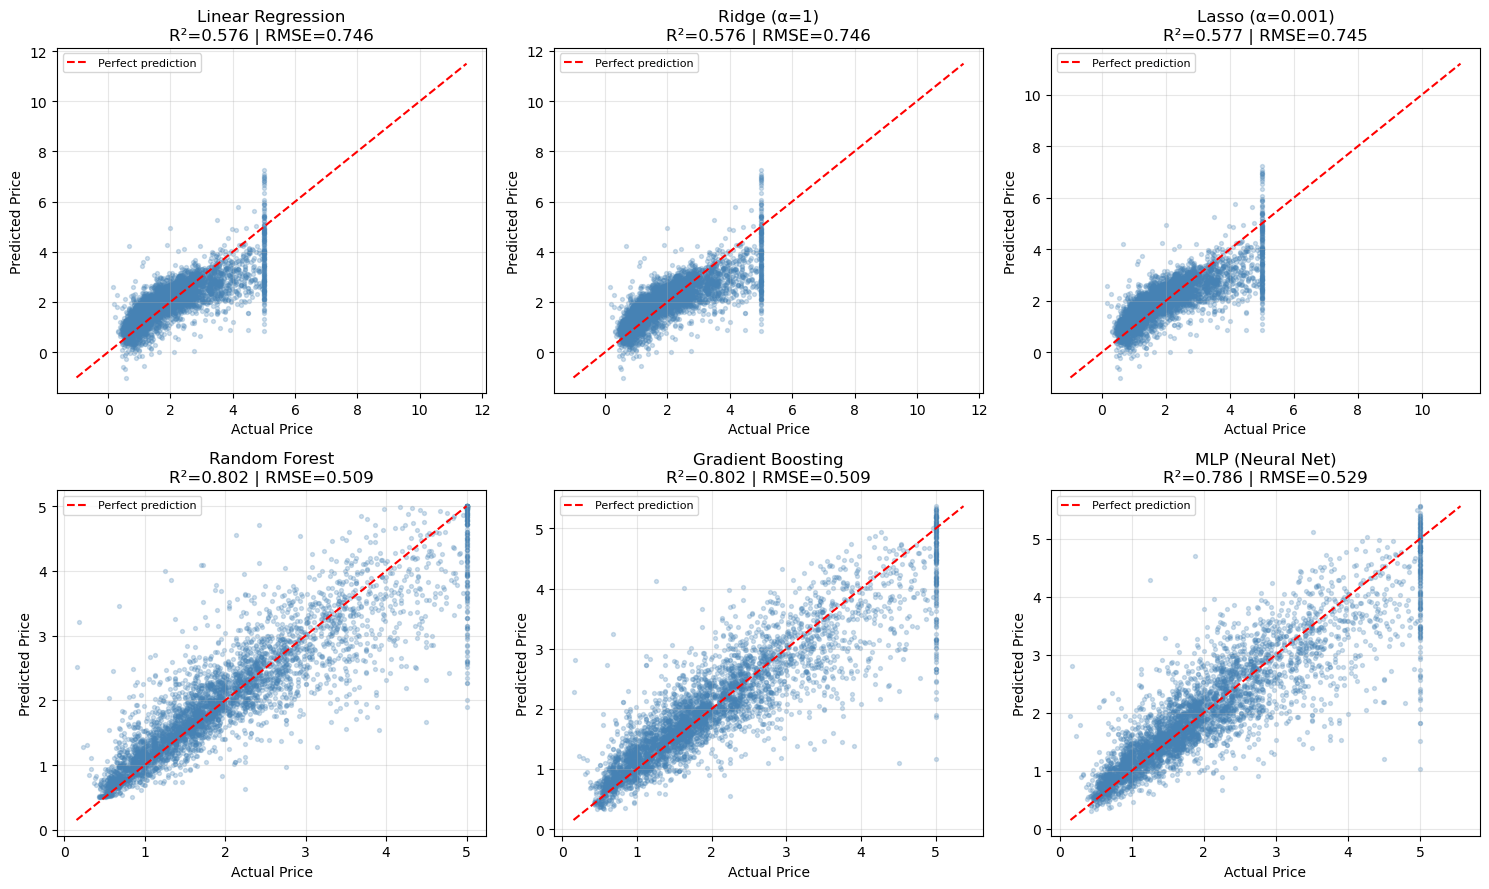


Generating error learning curves (RMSE)...
Linear Regression: final train RMSE=0.7196 | CV RMSE=0.7205 | gap=+0.0010
Ridge (α=1): final train RMSE=0.7196 | CV RMSE=0.7205 | gap=+0.0010
Lasso (α=0.001): final train RMSE=0.7196 | CV RMSE=0.7205 | gap=+0.0009
Random Forest: final train RMSE=0.2332 | CV RMSE=0.5129 | gap=+0.2797
Gradient Boosting: final train RMSE=0.4547 | CV RMSE=0.5061 | gap=+0.0515
MLP (Neural Net): final train RMSE=0.4964 | CV RMSE=0.5320 | gap=+0.0356


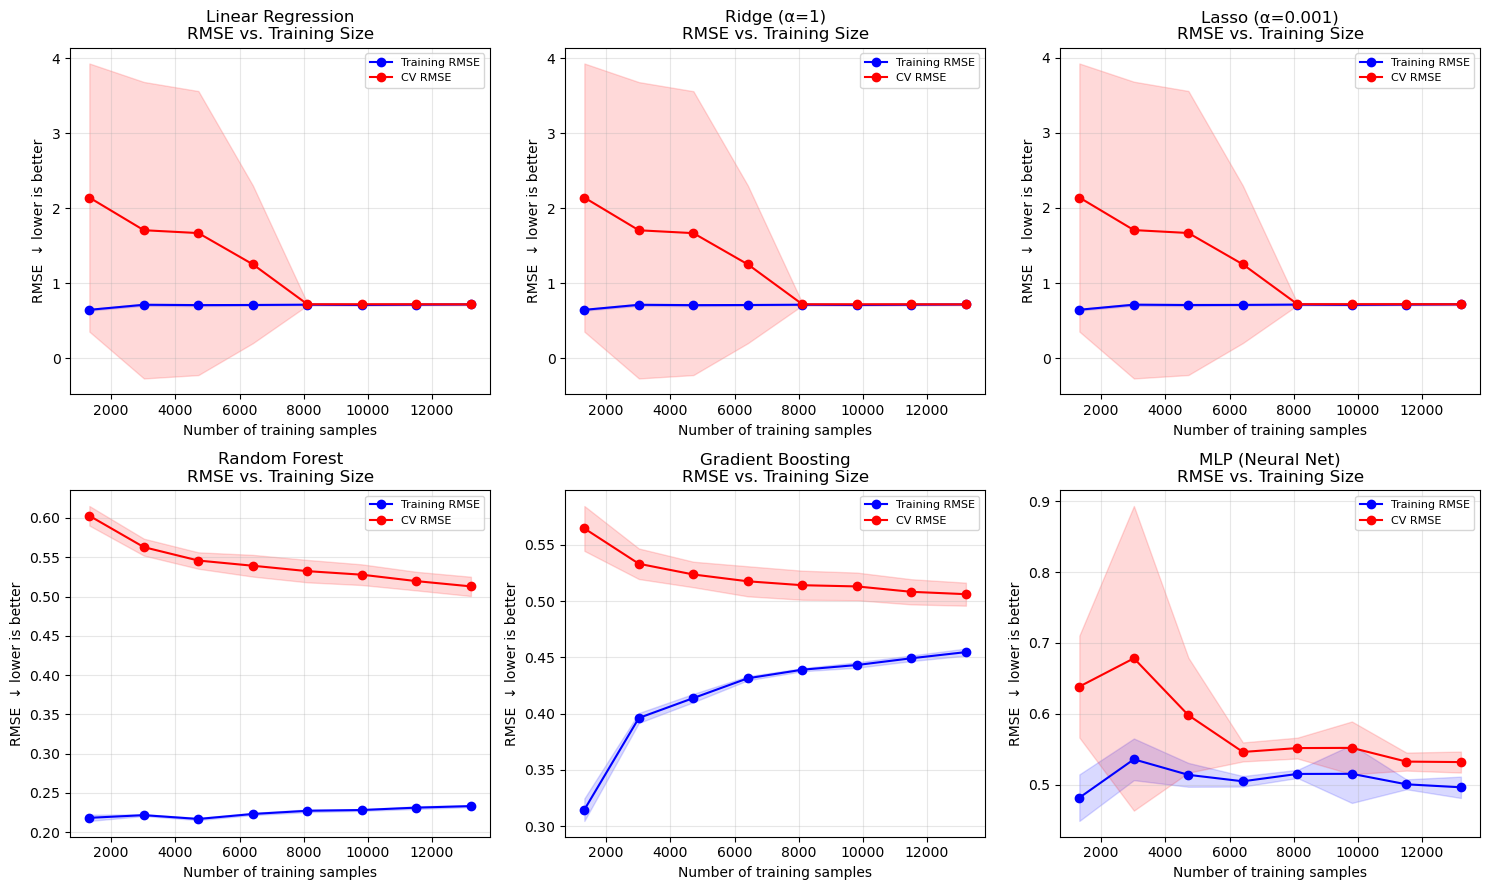


Interpretation:
  - Large positive gap (CV RMSE >> train RMSE) -> OVERFITTING
  - Both RMSE high and close together          -> UNDERFITTING
  - Both low and converging                    -> GOOD FIT

Analysis Complete.


In [1]:
# ==============================================================================
# REGRESSION BENCHMARK — CALIFORNIA HOUSING
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, KFold, cross_validate, learning_curve
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             mean_absolute_percentage_error,
                             mean_squared_log_error, make_scorer)

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor

# ==============================================================================
# 1. DATA
# ==============================================================================
print("Loading California Housing...")
housing = fetch_california_housing(as_frame=True)
df = housing.frame

# Rename target for clarity
df = df.rename(columns={'MedHouseVal': 'Price'})

X = df.drop(columns=['Price'])
y = df['Price']

print(f"Samples: {X.shape[0]} | Features: {X.shape[1]}")
print(f"Target range: {y.min():.2f} – {y.max():.2f} (units of $100,000)")
print(f"Target mean: {y.mean():.2f} | std: {y.std():.2f}")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ==============================================================================
# 2. MODELS
# ==============================================================================
models = {
    'Linear Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('reg', LinearRegression())
    ]),
    'Ridge (α=1)': Pipeline([
        ('scaler', StandardScaler()),
        ('reg', Ridge(alpha=1.0, random_state=42))
    ]),
    'Lasso (α=0.001)': Pipeline([
        ('scaler', StandardScaler()),
        ('reg', Lasso(alpha=0.001, max_iter=5000, random_state=42))
    ]),
    'Random Forest': RandomForestRegressor(
        n_estimators=200, max_depth=15, random_state=42, n_jobs=-1
    ),
    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=200, learning_rate=0.05, max_depth=4, random_state=42
    ),
    'MLP (Neural Net)': Pipeline([
        ('scaler', StandardScaler()),
        ('reg', MLPRegressor(hidden_layer_sizes=(128, 64), max_iter=500,
                             early_stopping=True, random_state=42))
    ]),
}

# ==============================================================================
# 3. SCORERS (all regression-appropriate)
# ==============================================================================
def msle_scorer(y_true, y_pred):
    """MSLE requires non-negative targets; clip to safe positive range."""
    return mean_squared_log_error(np.clip(y_true, 0, None),
                                  np.clip(y_pred, 0, None))

scoring = {
    'mae':   'neg_mean_absolute_error',
    'mse':   'neg_mean_squared_error',
    'rmse':  'neg_root_mean_squared_error',
    'r2':    'r2',
    'mape':  make_scorer(mean_absolute_percentage_error, greater_is_better=False),
    'msle':  make_scorer(msle_scorer, greater_is_better=False),
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)

# ==============================================================================
# 4. CROSS-VALIDATION
# ==============================================================================
results = []
print("\nRunning 5-fold cross-validation...")
for name, model in models.items():
    print(f"  → {name}")
    scores = cross_validate(model, X_train, y_train, cv=cv,
                            scoring=scoring, n_jobs=-1)

    results.append({
        'Model':       name,
        'R² (mean)':   scores['test_r2'].mean(),
        'R² (std)':    scores['test_r2'].std(),
        'MAE':         -scores['test_mae'].mean(),
        'RMSE':        -scores['test_rmse'].mean(),
        'MAPE (%)':    -scores['test_mape'].mean() * 100,
        'MSLE':        -scores['test_msle'].mean(),
    })

results_df = pd.DataFrame(results).sort_values('R² (mean)', ascending=False)
print("\n=== Cross-Validation Results ===")
print(results_df.to_string(index=False, float_format=lambda x: f'{x:.4f}'))

# ==============================================================================
# 5. TEST-SET EVALUATION & PREDICTION PLOTS
# ==============================================================================
n_models = len(models)
n_cols = 3
n_rows = int(np.ceil(n_models / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4.5 * n_rows))
axes = axes.flatten()

print("\n=== Test-Set Performance & Generalization Gap ===")
for i, (name, model) in enumerate(models.items()):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # Metrics
    mae  = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2   = r2_score(y_test, y_pred)

    # Generalization gap (RMSE-based)
    train_pred = model.predict(X_train)
    train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
    gap = rmse - train_rmse

    print(f"\n{name}")
    print(f"  Test  → MAE={mae:.4f} | RMSE={rmse:.4f} | R²={r2:.4f}")
    print(f"  Train → RMSE={train_rmse:.4f} | Generalization gap (RMSE) = {gap:+.4f}")

    # Scatter: predicted vs actual
    axes[i].scatter(y_test, y_pred, alpha=0.25, s=8, color='steelblue')
    lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
    axes[i].plot(lims, lims, 'r--', lw=1.5, label='Perfect prediction')
    axes[i].set_xlabel('Actual Price')
    axes[i].set_ylabel('Predicted Price')
    axes[i].set_title(f'{name}\nR²={r2:.3f} | RMSE={rmse:.3f}')
    axes[i].legend(loc='upper left', fontsize=8)
    axes[i].grid(True, alpha=0.3)

for j in range(i + 1, len(axes)):
    axes[j].axis('off')
plt.tight_layout()
plt.show()

# ==============================================================================
# 6. ERROR LEARNING CURVES (RMSE vs. training size)
# ==============================================================================
print("\nGenerating error learning curves (RMSE)...")
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4.5 * n_rows))
axes = axes.flatten()

train_sizes = np.linspace(0.1, 1.0, 8)

for i, (name, model) in enumerate(models.items()):
    train_sizes_abs, train_scores, val_scores = learning_curve(
        model, X_train, y_train,
        train_sizes=train_sizes, cv=cv,
        scoring='neg_root_mean_squared_error',
        n_jobs=-1, random_state=42
    )

    # Convert negative scores to positive RMSE
    train_rmse = -train_scores
    val_rmse   = -val_scores

    tr_mean, tr_std = train_rmse.mean(axis=1), train_rmse.std(axis=1)
    va_mean, va_std = val_rmse.mean(axis=1),   val_rmse.std(axis=1)

    axes[i].plot(train_sizes_abs, tr_mean, 'o-', color='blue',
                 label='Training RMSE')
    axes[i].fill_between(train_sizes_abs, tr_mean - tr_std, tr_mean + tr_std,
                         alpha=0.15, color='blue')

    axes[i].plot(train_sizes_abs, va_mean, 'o-', color='red',
                 label='CV RMSE')
    axes[i].fill_between(train_sizes_abs, va_mean - va_std, va_mean + va_std,
                         alpha=0.15, color='red')

    axes[i].set_title(f'{name}\nRMSE vs. Training Size')
    axes[i].set_xlabel('Number of training samples')
    axes[i].set_ylabel('RMSE  ↓ lower is better')
    axes[i].legend(loc='best', fontsize=8)
    axes[i].grid(True, alpha=0.3)

    final_gap = va_mean[-1] - tr_mean[-1]
    print(f"{name}: final train RMSE={tr_mean[-1]:.4f} | "
          f"CV RMSE={va_mean[-1]:.4f} | gap={final_gap:+.4f}")

for j in range(i + 1, len(axes)):
    axes[j].axis('off')
plt.tight_layout()
plt.show()

print("\nInterpretation:")
print("  - Large positive gap (CV RMSE >> train RMSE) -> OVERFITTING")
print("  - Both RMSE high and close together          -> UNDERFITTING")
print("  - Both low and converging                    -> GOOD FIT")
print("\nAnalysis Complete.")